## **Random walk visualization**

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import rayleigh
import random

In [2]:
rng = np.random.default_rng(42)
def random_walk_1d(n_walkers, n_steps, p=[0.5, 0.5]):
    """Simulates a 1D random walk for n_steps."""
    positions = rng.choice([-1, 1], p = p, size = (n_walkers,n_steps))
    return np.cumsum(positions, axis = 1)

In [3]:
def random_walk_2d(n_walkers, n_steps, p=[0.25]*4):
  steps = np.array([[0, 1], [0, -1], [1, 0], [-1, 0]])

  random_ind = rng.choice(len(steps), p = p, size=(n_walkers, n_steps))
  random_steps = steps[random_ind]

  return np.sum(random_steps, axis=1)

## **1D Random Walk**

In [4]:
n_steps = 1000
walk_1d_positions = random_walk_1d(n_steps, n_steps)
walk_1d_positions = walk_1d_positions[:,-1]
print(np.sqrt(n_steps))
print(np.std(walk_1d_positions)) #should be the same as np.sqrt(n)
print(np.mean(walk_1d_positions)) # should be around 0 to follow normal dist.

31.622776601683793
30.70883592713993
-0.414


In [5]:
def plot_1D(walk_1d_positions):
  plt.figure(figsize=(10, 6))
  plt.plot(walk_1d_positions, marker='o', markersize=2)
  plt.title("1D Random Walk")
  plt.xlabel("Number of Steps")
  plt.ylabel("Final Position")
  plt.grid(True)
  plt.show()

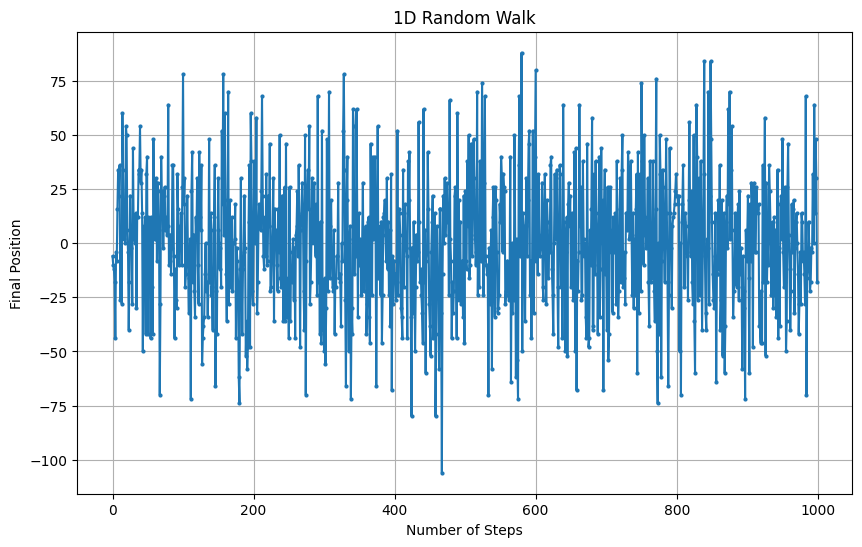

In [6]:
plot_1D(walk_1d_positions)

In [7]:
def hist_1D(walk_1d_positions, n_steps):
  plt.figure(figsize=(10, 5))
  sns.histplot(walk_1d_positions, kde=True, color='skyblue', stat="density")
  plt.title(f"Distribution 1D Random Walk after {n_steps} Steps")
  plt.xlabel("Final Position")
  plt.ylabel("Density")

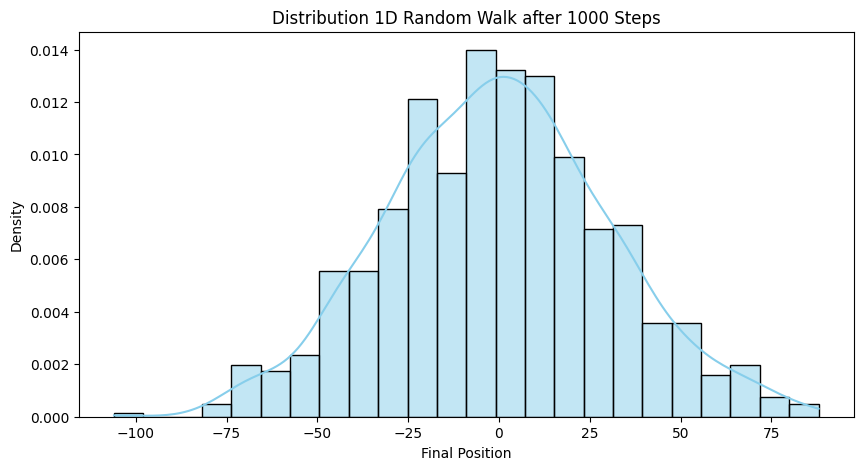

In [8]:
hist_1D(walk_1d_positions, n_steps)

## **2D Random Walk**

In [11]:
n_steps = 1000
paths = random_walk_2d(n_steps, n_steps)
x, y = paths[:,0], paths[:, 1]

Heatmap - KDE density

In [9]:
def kdeplot_2D(x, y):
  plt.figure(figsize=(8, 6))
  sns.kdeplot(x=x, y=y, cmap="viridis", fill=True, thresh=0, levels=100)
  plt.title("2D Random Walk Probability Density (KDE)")
  plt.xlabel("X Position")
  plt.ylabel("Y Position")
  plt.show()

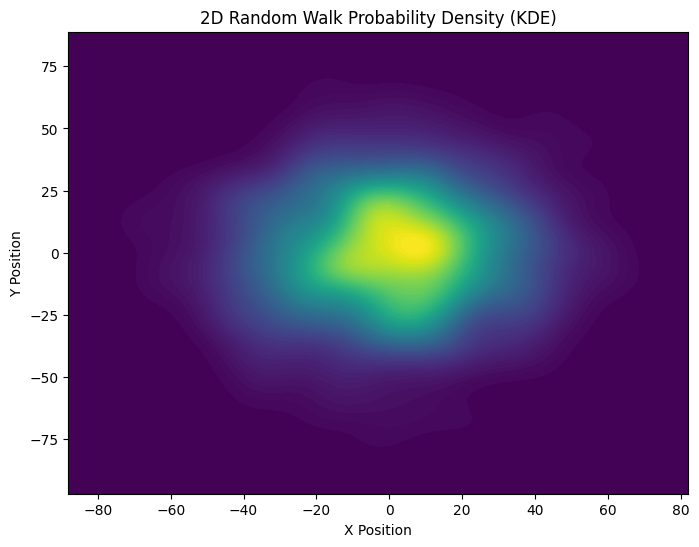

In [12]:
kdeplot_2D(x, y)

In [13]:
def jointplot_2D(x, y):
  g = sns.jointplot(
      data=pd.DataFrame({'x': x, 'y': y}),
      x='x',
      y='y',
      kind='kde',
      fill=True,
      cmap="Greens"
  )
  g.fig.suptitle('Density of 2D Random walk', y=1.02)
  plt.show()

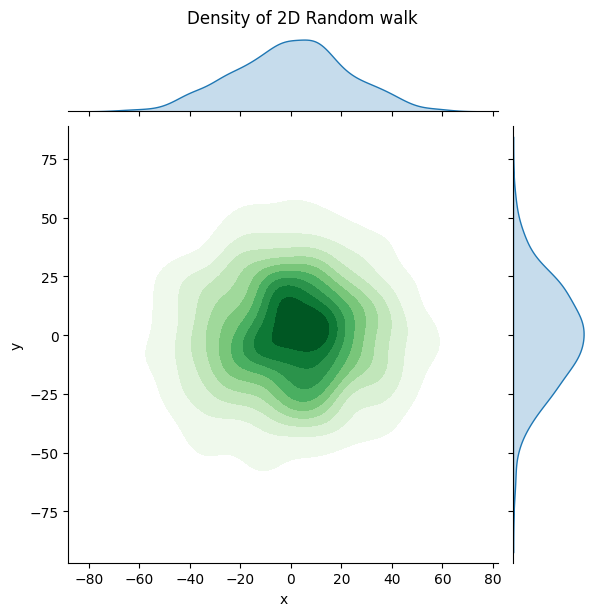

In [14]:
jointplot_2D(x, y)

Density of final distances from (0,0). Should follow a Rayleigh distribution for two independent normally distributed random variables x and y.

In [15]:
square_position = np.square(paths)
distances = np.sqrt(np.sum(square_position, axis = 1))

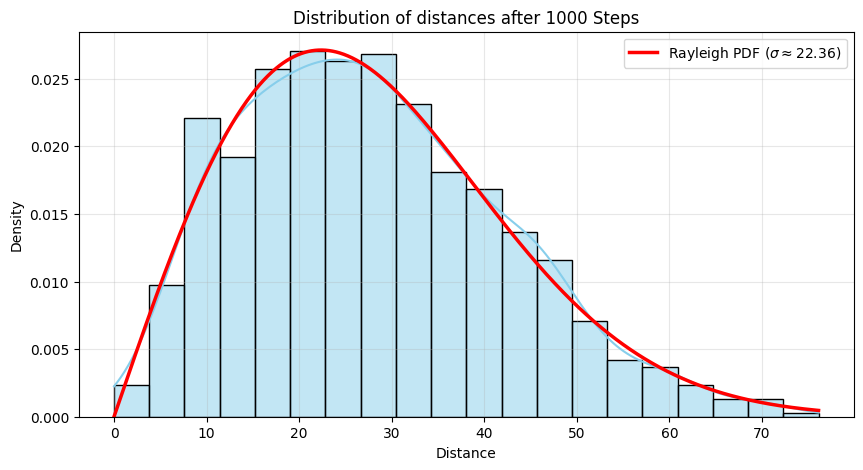

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(distances, kde=True, color='skyblue', stat="density")

sigma_rayleigh = np.sqrt(n_steps * 0.5)
x = np.linspace(0, np.max(distances), 1000)
pdf = rayleigh.pdf(x, scale=sigma_rayleigh)

plt.plot(x, pdf, 'r-', lw=2.5, label=f'Rayleigh PDF ($\\sigma \\approx {sigma_rayleigh:.2f}$)')

plt.title(f"Distribution of distances after {n_steps} Steps")
plt.xlabel("Distance")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Comparing mean and std to theoretical Rayleigh mean and std

In [17]:
print(np.mean(distances))
print(1.253 * sigma_rayleigh)
print(np.std(distances))
print(0.655 * sigma_rayleigh)

27.88109707001917
28.017931758072365
14.16228887476062
14.646245252623624


Bias to 1D Random Walk

In [18]:
n_steps = 1000
walk_1d_positions = random_walk_1d(n_steps, n_steps, p=[0.4, 0.6])
walk_1d_positions = walk_1d_positions[:,-1]
print(np.sqrt(n_steps))
print(np.std(walk_1d_positions)) #should be the same as np.sqrt(n)
print(np.mean(walk_1d_positions)) # should be shifted from 0 (around 200 = 600-400)

31.622776601683793
31.46416876384946
199.078


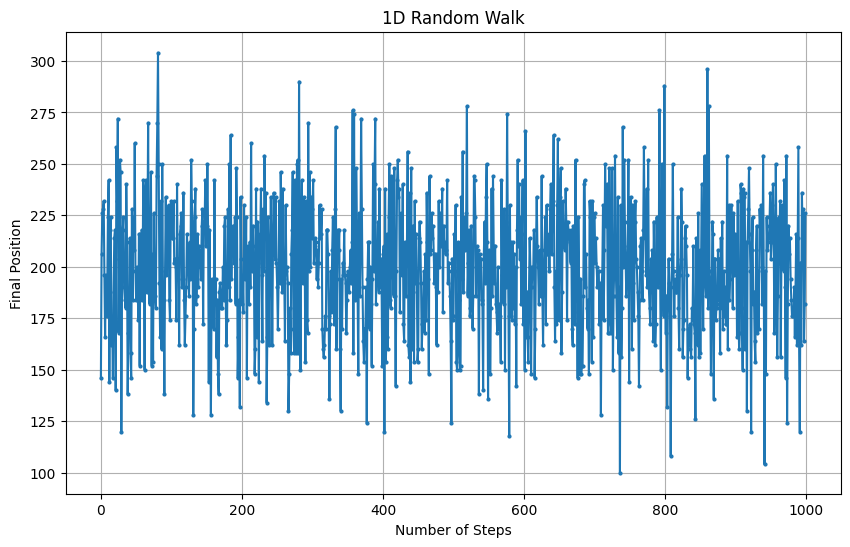

In [19]:
plot_1D(walk_1d_positions)

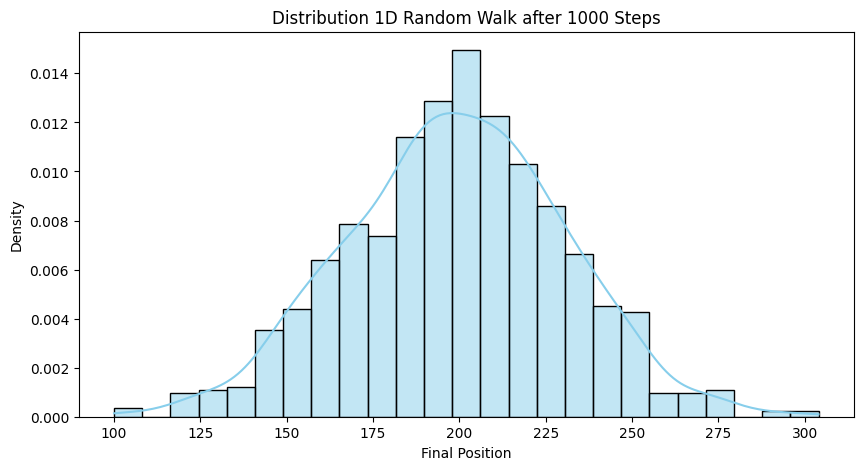

In [20]:
hist_1D(walk_1d_positions, n_steps)

Bias to 2D Random Walk

In [21]:
n_steps = 1000
paths = random_walk_2d(n_steps, n_steps, p = [0.45, 0.05, 0.05, 0.45])
x, y = paths[:,0], paths[:, 1]

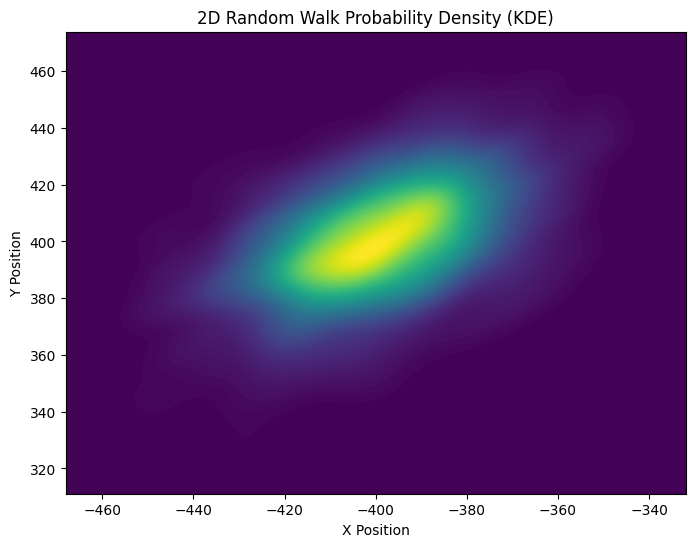

In [22]:
kdeplot_2D(x, y)

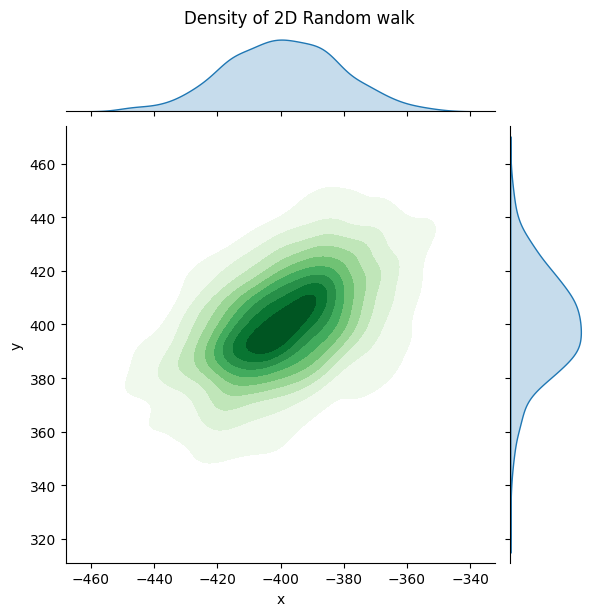

In [24]:
jointplot_2D(x, y)

In [25]:
square_position = np.square(paths)
distances = np.sqrt(np.sum(square_position, axis = 1))

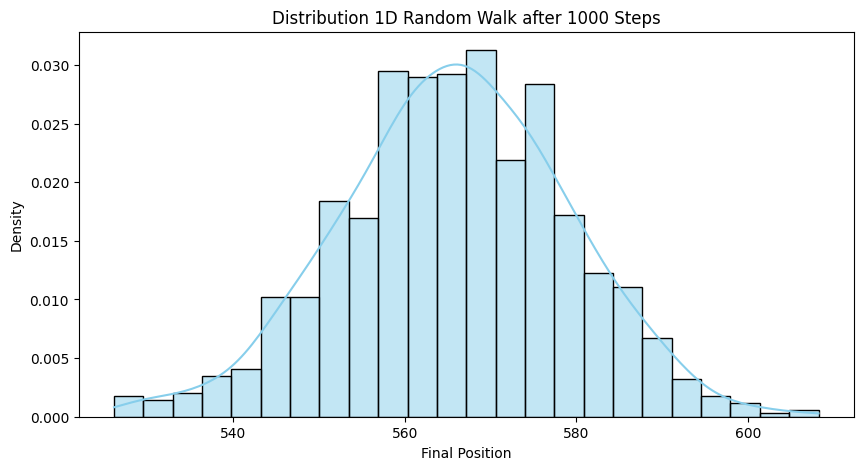

In [26]:
hist_1D(distances, n_steps)